In [1]:
!pip install lightgbm
!pip install catboost


[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
!pip install lightgbm imbalanced-learn -q


[notice] A new release of pip is available: 25.2 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    roc_auc_score, confusion_matrix, roc_curve,
    classification_report, f1_score
)

# SMOTE
from imblearn.over_sampling import SMOTE

# Classifiers
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from catboost import CatBoostClassifier
import lightgbm as lgb
from sklearn.neural_network import MLPClassifier

# AutoEncoder
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping

print('✅ Semua library berhasil diimport.')

✅ Semua library berhasil diimport.


In [4]:
df = pd.read_csv('creditcard1.csv')
print(f"Shape dataset: {df.shape}")
df.head()

Shape dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Transaksi Sah (0)      : 284315 (99.827%)
Transaksi Penipuan (1) : 492 (0.173%)


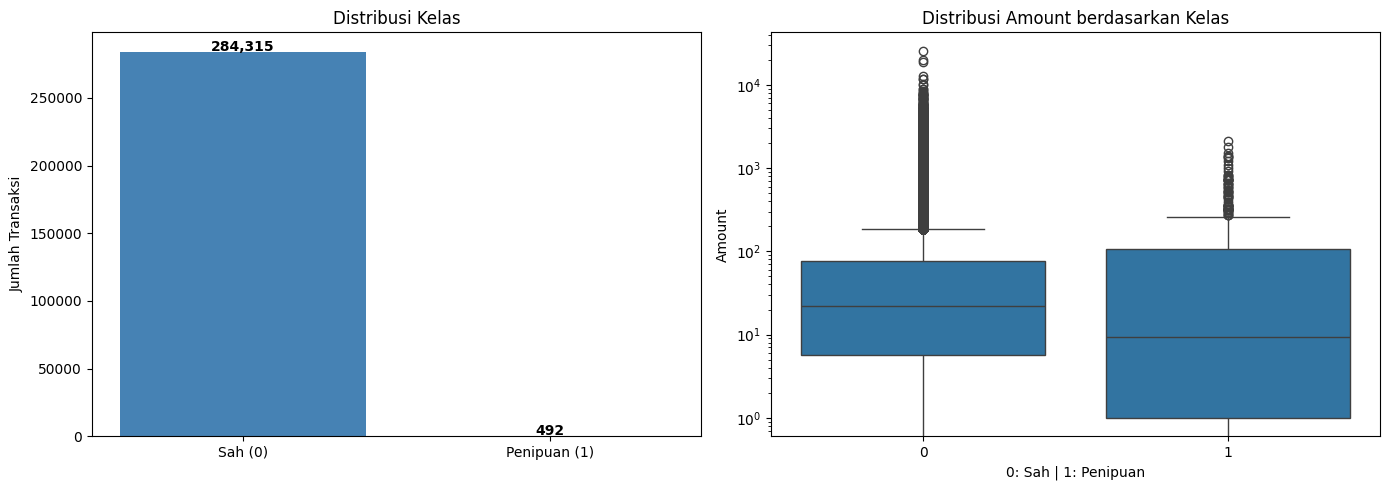

In [5]:
class_counts = df['Class'].value_counts()
print(f"Transaksi Sah (0)      : {class_counts[0]} ({class_counts[0]/len(df)*100:.3f}%)")
print(f"Transaksi Penipuan (1) : {class_counts[1]} ({class_counts[1]/len(df)*100:.3f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribusi kelas
axes[0].bar(['Sah (0)', 'Penipuan (1)'], [class_counts[0], class_counts[1]],
            color=['steelblue', 'tomato'])
axes[0].set_title('Distribusi Kelas')
axes[0].set_ylabel('Jumlah Transaksi')
for i, v in enumerate([class_counts[0], class_counts[1]]):
    axes[0].text(i, v + 500, f'{v:,}', ha='center', fontweight='bold')

# Distribusi amount
sns.boxplot(x=df['Class'], y=df['Amount'], ax=axes[1])
axes[1].set_title('Distribusi Amount berdasarkan Kelas')
axes[1].set_xlabel('0: Sah | 1: Penipuan')
axes[1].set_yscale('log')

plt.tight_layout()
plt.show()

In [6]:
# Handle missing values
if df.isnull().sum().max() > 0:
    df = df.fillna(df.mean())
    print("Missing values diisi dengan mean.")
else:
    print("Tidak ada missing values.")

X = df.drop(['Class', 'Time'], axis=1).values
y = df['Class'].values

print(f"Shape X : {X.shape}")
print(f"Shape y : {y.shape}")

Tidak ada missing values.
Shape X : (284807, 29)
Shape y : (284807,)


SPLIT

In [7]:
def build_autoencoder(input_dim):
    """AutoEncoder — sama untuk semua model & semua fold."""
    inp     = Input(shape=(input_dim,))
    enc     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(inp)
    latent  = Dense(256, activation='relu', kernel_regularizer=l2(0.001))(enc)
    dec     = Dense(512, activation='relu', kernel_regularizer=l2(0.001))(latent)
    out     = Dense(input_dim, activation='linear')(dec)

    ae      = Model(inputs=inp, outputs=out)
    encoder = Model(inputs=inp, outputs=latent)
    ae.compile(optimizer=Adam(learning_rate=0.0001), loss='binary_crossentropy')
    return ae, encoder


def extract_hybrid_features(ae, encoder, X_tr, X_te):
    """Gabung: Original Features + Latent Space + MSE Reconstruction Error."""
    mse_tr  = np.mean(np.power(X_tr - ae.predict(X_tr, verbose=0), 2), axis=1, keepdims=True)
    mse_te  = np.mean(np.power(X_te - ae.predict(X_te, verbose=0), 2), axis=1, keepdims=True)
    lat_tr  = encoder.predict(X_tr, verbose=0)
    lat_te  = encoder.predict(X_te, verbose=0)
    return np.hstack((X_tr, lat_tr, mse_tr)), np.hstack((X_te, lat_te, mse_te))


def apply_smote(X_hybrid_train, y_train, fold_num):
    """
    SMOTE diterapkan HANYA pada X_train_hybrid (Pilihan B).
    X_test tidak disentuh — tetap distribusi asli.
    """
    sm = SMOTE(random_state=42, k_neighbors=5)
    X_res, y_res = sm.fit_resample(X_hybrid_train, y_train)
    fraud_before = int(np.sum(y_train == 1))
    fraud_after  = int(np.sum(y_res == 1))
    print(f'[Fold {fold_num}] SMOTE: fraud {fraud_before} → {fraud_after} | '
          f'total train {len(y_train)} → {len(y_res)}')
    return X_res, y_res


def find_optimal_threshold(model, X_val, y_val, w=0.70):
    """Weighted Youden Index: prioritaskan Detection Rate."""
    prob = model.predict_proba(X_val)[:, 1]
    fpr, tpr, thresholds = roc_curve(y_val, prob)
    score = (w * tpr) - ((1 - w) * fpr)
    best_t = thresholds[np.argmax(score)]
    # Batasi threshold agar tidak terlalu ekstrem
    return float(best_t)


print('Fungsi helper siap.')

Fungsi helper siap.


SPLIT DATA 80 20

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = {
    'AE + XGBoost'      : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Random Forest' : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + Catboost'           : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + LightGBM'      : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
    'AE + MLP'           : {'acc':[],'prec':[],'dr':[],'auc':[],'f1':[]},
}

last_fold = {}

for fold_num, (train_idx, test_idx) in enumerate(skf.split(X, y), start=1):
    print(f'\n{"="*55}')
    print(f'                   FOLD {fold_num} / 5')
    print(f'{"="*55}')

    X_train_raw, X_test_raw = X[train_idx], X[test_idx]
    y_train, y_test         = y[train_idx], y[test_idx]

    # ── Scaling ──────────────────────────────────────────────
    scaler  = StandardScaler()
    X_train = scaler.fit_transform(X_train_raw)
    X_test  = scaler.transform(X_test_raw)

    print(f'Train: {X_train.shape} | Test: {X_test.shape}')
    print(f'Fraud di train: {sum(y_train)} | Fraud di test: {sum(y_test)}')

    # ── AutoEncoder ───────────────────────────────────────────
    # Ditraining hanya dengan data NORMAL (Class=0)
    X_train_normal = X_train[y_train == 0]
    ae, encoder = build_autoencoder(X_train.shape[1])
    ae.fit(
        X_train_normal, X_train_normal,
        epochs=50, batch_size=64, validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=5,
                                 restore_best_weights=True)],
        verbose=0
    )
    print(f'[Fold {fold_num}] AutoEncoder selesai (training dari data normal saja).')

    # ── Ekstraksi Fitur Hybrid ────────────────────────────────
    X_train_hybrid, X_test_hybrid = extract_hybrid_features(
        ae, encoder, X_train, X_test
    )
    print(f'[Fold {fold_num}] Dimensi hybrid: {X_train_hybrid.shape[1]} fitur')

    # ── SMOTE  ─────────────────────────────────────
    # ── 1. Pisah Val Set untuk threshold (DARI DATA HYBRID ASLI) ──
    X_tr_raw, X_val, y_tr_raw, y_val = train_test_split(
        X_train_hybrid, y_train, 
        test_size=0.2, stratify=y_train, random_state=42
    )

    # ── 2. SMOTE (Hanya diaplikasikan pada X_tr_raw) ──
    X_tr, y_tr = apply_smote(
        X_tr_raw, y_tr_raw, fold_num
    )
    print(f'[Fold {fold_num}] Data Train setelah SMOTE: {X_tr.shape} | Data Val Asli: {X_val.shape}')

    # ════════════════════════════════════════
    # MODEL 1 — AE + XGBoost
    # ════════════════════════════════════════
    m1 = xgb.XGBClassifier(
        n_estimators=200, learning_rate=0.05, max_depth=6,
        min_child_weight=5, subsample=0.8, colsample_bytree=0.8,
        random_state=42, eval_metric='auc', verbosity=0
    )
    m1.fit(X_tr, y_tr)
    t1    = find_optimal_threshold(m1, X_val, y_val)
    prob1 = m1.predict_proba(X_test_hybrid)[:, 1]
    pred1 = (prob1 >= t1).astype(int)
    results['AE + XGBoost']['acc'].append(accuracy_score(y_test, pred1)*100)
    results['AE + XGBoost']['prec'].append(precision_score(y_test, pred1, zero_division=0)*100)
    results['AE + XGBoost']['dr'].append(recall_score(y_test, pred1)*100)
    results['AE + XGBoost']['auc'].append(roc_auc_score(y_test, prob1)*100)
    results['AE + XGBoost']['f1'].append(f1_score(y_test, pred1, zero_division=0)*100)
    print(f'[Fold {fold_num}] XGBoost      Acc:{results["AE + XGBoost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + XGBoost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + XGBoost"]["auc"][-1]:.2f}% '
          f'(threshold={t1:.3f})')

    # ════════════════════════════════════════
    # MODEL 2 — AE + Random Forest
    # ════════════════════════════════════════
    m2 = RandomForestClassifier(
        n_estimators=200, max_depth=None,
        n_jobs=-1, random_state=42
        # Tidak pakai class_weight karena SMOTE sudah balance
    )
    m2.fit(X_tr, y_tr)
    t2    = find_optimal_threshold(m2, X_val, y_val)
    prob2 = m2.predict_proba(X_test_hybrid)[:, 1]
    pred2 = (prob2 >= t2).astype(int)
    results['AE + Random Forest']['acc'].append(accuracy_score(y_test, pred2)*100)
    results['AE + Random Forest']['prec'].append(precision_score(y_test, pred2, zero_division=0)*100)
    results['AE + Random Forest']['dr'].append(recall_score(y_test, pred2)*100)
    results['AE + Random Forest']['auc'].append(roc_auc_score(y_test, prob2)*100)
    results['AE + Random Forest']['f1'].append(f1_score(y_test, pred2, zero_division=0)*100)
    print(f'[Fold {fold_num}] Rnd Forest   Acc:{results["AE + Random Forest"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Random Forest"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Random Forest"]["auc"][-1]:.2f}% '
          f'(threshold={t2:.3f})')

    # ════════════════════════════════════════
    # MODEL 3 — AE + Catboost
    # ════════════════════════════════════════
    m3 = CatBoostClassifier(
    iterations=200, 
    learning_rate=0.05, 
    depth=6,
    random_state=42, 
    verbose=0
    )
    m3.fit(X_tr, y_tr)
    t3    = find_optimal_threshold(m3, X_val, y_val)
    prob3 = m3.predict_proba(X_test_hybrid)[:, 1]
    pred3 = (prob3 >= t3).astype(int)
    results['AE + Catboost']['acc'].append(accuracy_score(y_test, pred3)*100)
    results['AE + Catboost']['prec'].append(precision_score(y_test, pred3, zero_division=0)*100)
    results['AE + Catboost']['dr'].append(recall_score(y_test, pred3)*100)
    results['AE + Catboost']['auc'].append(roc_auc_score(y_test, prob3)*100)
    results['AE + Catboost']['f1'].append(f1_score(y_test, pred3, zero_division=0)*100)
    print(f'[Fold {fold_num}] Catboost          Acc:{results["AE + Catboost"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + Catboost"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + Catboost"]["auc"][-1]:.2f}% '
          f'(threshold={t3:.3f})')

    # ════════════════════════════════════════
    # MODEL 4 — AE + LightGBM
    # ════════════════════════════════════════
    m4 = lgb.LGBMClassifier(
        n_estimators=200, learning_rate=0.05,
        max_depth=6, subsample=0.8, colsample_bytree=0.8,
        is_unbalance=False,   # False karena SMOTE sudah handle
        random_state=42, verbose=-1
    )
    m4.fit(X_tr, y_tr)
    t4    = find_optimal_threshold(m4, X_val, y_val)
    prob4 = m4.predict_proba(X_test_hybrid)[:, 1]
    pred4 = (prob4 >= t4).astype(int)
    results['AE + LightGBM']['acc'].append(accuracy_score(y_test, pred4)*100)
    results['AE + LightGBM']['prec'].append(precision_score(y_test, pred4, zero_division=0)*100)
    results['AE + LightGBM']['dr'].append(recall_score(y_test, pred4)*100)
    results['AE + LightGBM']['auc'].append(roc_auc_score(y_test, prob4)*100)
    results['AE + LightGBM']['f1'].append(f1_score(y_test, pred4, zero_division=0)*100)
    print(f'[Fold {fold_num}] LightGBM     Acc:{results["AE + LightGBM"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + LightGBM"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + LightGBM"]["auc"][-1]:.2f}% '
          f'(threshold={t4:.3f})')

    # ════════════════════════════════════════
    # MODEL 5 — AE + MLP
    # ════════════════════════════════════════
    m5 = MLPClassifier(
        hidden_layer_sizes=(256, 128, 64),
        activation='relu', solver='adam',
        learning_rate_init=0.001, max_iter=200,
        early_stopping=True, validation_fraction=0.1,
        random_state=42
    )
    m5.fit(X_tr, y_tr)
    t5    = find_optimal_threshold(m5, X_val, y_val)
    prob5 = m5.predict_proba(X_test_hybrid)[:, 1]
    pred5 = (prob5 >= t5).astype(int)
    results['AE + MLP']['acc'].append(accuracy_score(y_test, pred5)*100)
    results['AE + MLP']['prec'].append(precision_score(y_test, pred5, zero_division=0)*100)
    results['AE + MLP']['dr'].append(recall_score(y_test, pred5)*100)
    results['AE + MLP']['auc'].append(roc_auc_score(y_test, prob5)*100)
    results['AE + MLP']['f1'].append(f1_score(y_test, pred5, zero_division=0)*100)
    print(f'[Fold {fold_num}] MLP          Acc:{results["AE + MLP"]["acc"][-1]:.2f}% '
          f'DR:{results["AE + MLP"]["dr"][-1]:.2f}% '
          f'AUC:{results["AE + MLP"]["auc"][-1]:.2f}% '
          f'(threshold={t5:.3f})')

    if fold_num == 5:
        last_fold = {
            'AE + XGBoost'      : (y_test, pred1, prob1),
            'AE + Random Forest' : (y_test, pred2, prob2),
            'AE + Catboost'           : (y_test, pred3, prob3),
            'AE + LightGBM'      : (y_test, pred4, prob4),
            'AE + MLP'           : (y_test, pred5, prob5),
        }

print('\n' + '='*55)
print('Training & evaluasi selesai untuk semua fold.')
print('='*55)


                   FOLD 1 / 5
Train: (227845, 29) | Test: (56962, 29)
Fraud di train: 393 | Fraud di test: 99
[Fold 1] AutoEncoder selesai (training dari data normal saja).
[Fold 1] Dimensi hybrid: 286 fitur
[Fold 1] SMOTE: fraud 314 → 181962 | total train 182276 → 363924
[Fold 1] Data Train setelah SMOTE: (363924, 286) | Data Val Asli: (45569, 286)
[Fold 1] XGBoost      Acc:99.56% DR:85.86% AUC:97.18% (threshold=0.027)
[Fold 1] Rnd Forest   Acc:96.20% DR:89.90% AUC:97.90% (threshold=0.015)
[Fold 1] Catboost          Acc:97.41% DR:88.89% AUC:96.65% (threshold=0.014)
[Fold 1] LightGBM     Acc:99.33% DR:86.87% AUC:97.66% (threshold=0.009)
[Fold 1] MLP          Acc:97.17% DR:84.85% AUC:93.78% (threshold=0.000)

                   FOLD 2 / 5
Train: (227845, 29) | Test: (56962, 29)
Fraud di train: 393 | Fraud di test: 99
[Fold 2] AutoEncoder selesai (training dari data normal saja).
[Fold 2] Dimensi hybrid: 286 fitur
[Fold 2] SMOTE: fraud 314 → 181962 | total train 182276 → 363924
[Fold 2]

In [9]:
print("\n" + "="*85)
print("RINGKASAN HASIL RATA-RATA 5-FOLD CROSS VALIDATION")
print("="*85)
print(f"{'Model':<22} {'Accuracy':>14} {'Detection Rate':>16} {'AUC':>14} {'F1-Score':>12}")
print("-"*85)

summary_data = []
for model_name, scores in results.items():
    acc_mean = np.mean(scores['acc'])
    acc_std  = np.std(scores['acc'])
    dr_mean  = np.mean(scores['dr'])
    dr_std   = np.std(scores['dr'])
    auc_mean = np.mean(scores['auc'])
    auc_std  = np.std(scores['auc'])
    f1_mean  = np.mean(scores['f1'])
    f1_std   = np.std(scores['f1'])

    summary_data.append({
        'Model': model_name,
        'Accuracy': acc_mean,
        'Acc_std': acc_std,
        'Detection Rate': dr_mean,
        'DR_std': dr_std,
        'AUC': auc_mean,
        'AUC_std': auc_std,
        'F1-Score': f1_mean,
        'F1_std': f1_std,
    })

    print(f"{model_name:<22} "
          f"{acc_mean:>7.3f}±{acc_std:.2f}% "
          f"{dr_mean:>8.3f}±{dr_std:.2f}% "
          f"{auc_mean:>7.3f}±{auc_std:.2f}% "
          f"{f1_mean:>6.3f}±{f1_std:.2f}%")

print("-"*85)
print(f"{'(Target SOTA)':<22} {'≥95.130%':>14} {'≥91.176%':>16} {'≥93.156%':>14}")
print("="*85)

df_summary = pd.DataFrame(summary_data)
df_summary


RINGKASAN HASIL RATA-RATA 5-FOLD CROSS VALIDATION
Model                        Accuracy   Detection Rate            AUC     F1-Score
-------------------------------------------------------------------------------------
AE + XGBoost            95.526±3.03%   91.876±3.18%  98.043±0.89% 13.805±13.83%
AE + Random Forest      95.722±1.55%   94.317±2.68%  98.007±0.85%  7.793±2.31%
AE + Catboost           96.616±1.83%   91.058±2.76%  97.755±0.91% 11.235±5.93%
AE + LightGBM           96.527±1.87%   92.284±2.89%  98.084±0.59% 12.535±9.49%
AE + MLP                97.757±1.46%   87.394±2.71%  95.409±1.35% 21.952±21.49%
-------------------------------------------------------------------------------------
(Target SOTA)                ≥95.130%         ≥91.176%       ≥93.156%


,Model,Accuracy,Acc_std,Detection Rate,DR_std,AUC,AUC_std,F1-Score,F1_std
0,AE + XGBoost,95.526442,3.031959,91.875902,3.182013,98.042868,0.892947,13.805328,13.831659
1,AE + Random Forest,95.721656,1.548356,94.316636,2.675723,98.006666,0.852425,7.793020,2.308053
2,AE + Catboost,96.615947,1.832501,91.057514,2.759875,97.755424,0.905557,11.234844,5.925294
3,AE + LightGBM,96.526768,1.867198,92.284065,2.885764,98.083780,0.588810,12.535010,9.492243
4,AE + MLP,97.757431,1.464070,87.394352,2.705214,95.408969,1.351435,21.952438,21.491389


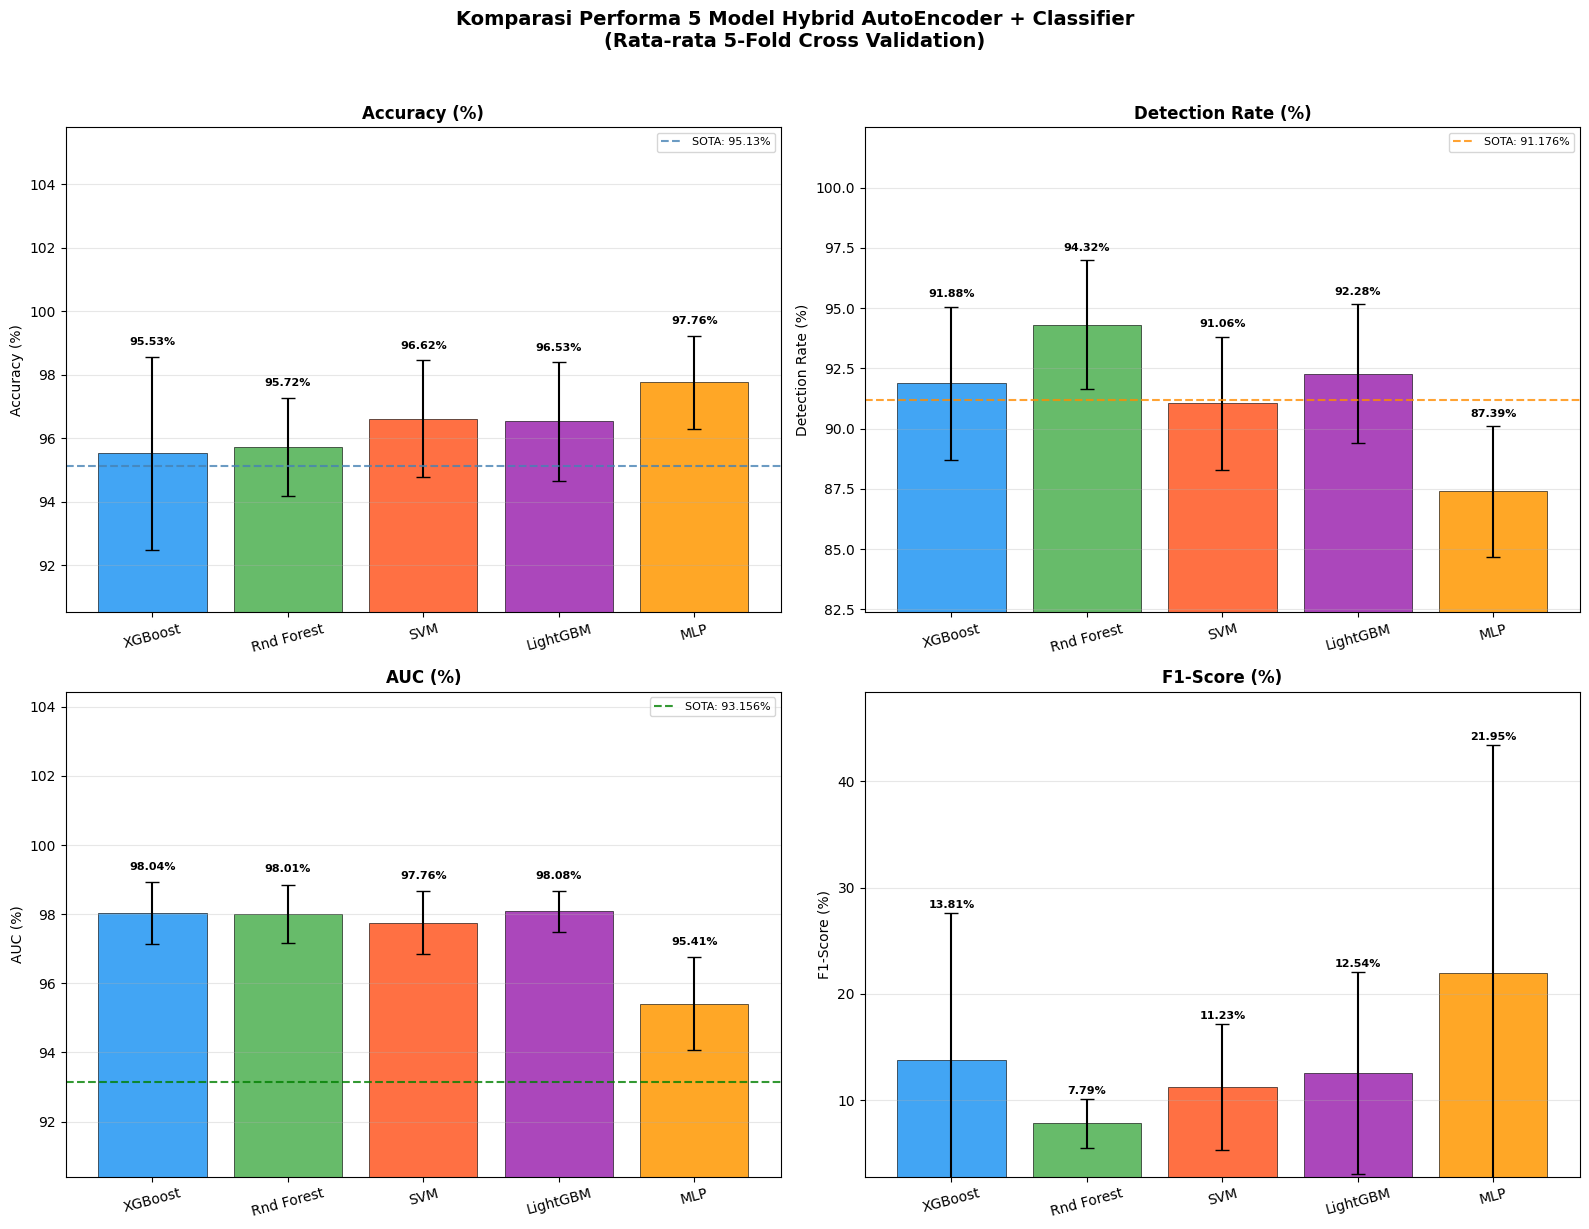

✅ Grafik disimpan sebagai komparasi_performa.png


In [10]:
model_names   = list(results.keys())
short_labels  = ['XGBoost', 'Rnd Forest', 'SVM', 'LightGBM', 'MLP']
colors        = ['#2196F3', '#4CAF50', '#FF5722', '#9C27B0', '#FF9800']

acc_means  = [np.mean(results[m]['acc']) for m in model_names]
dr_means   = [np.mean(results[m]['dr'])  for m in model_names]
auc_means  = [np.mean(results[m]['auc']) for m in model_names]
f1_means   = [np.mean(results[m]['f1'])  for m in model_names]

acc_stds   = [np.std(results[m]['acc']) for m in model_names]
dr_stds    = [np.std(results[m]['dr'])  for m in model_names]
auc_stds   = [np.std(results[m]['auc']) for m in model_names]
f1_stds    = [np.std(results[m]['f1'])  for m in model_names]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Komparasi Performa 5 Model Hybrid AutoEncoder + Classifier\n(Rata-rata 5-Fold Cross Validation)', 
             fontsize=14, fontweight='bold', y=1.02)

metrics = [
    ('Accuracy (%)',       acc_means, acc_stds,  axes[0,0], 95.130, 'steelblue'),
    ('Detection Rate (%)', dr_means,  dr_stds,   axes[0,1], 91.176, 'darkorange'),
    ('AUC (%)',            auc_means, auc_stds,  axes[1,0], 93.156, 'green'),
    ('F1-Score (%)',       f1_means,  f1_stds,   axes[1,1], None,   'purple'),
]

for metric_name, means, stds, ax, sota, sota_color in metrics:
    bars = ax.bar(short_labels, means, yerr=stds, capsize=5,
                  color=colors, alpha=0.85, edgecolor='black', linewidth=0.5)

    # Annotate nilai
    for bar, val, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + std + 0.3,
                f'{val:.2f}%', ha='center', va='bottom', fontsize=8, fontweight='bold')

    if sota:
        ax.axhline(y=sota, color=sota_color, linestyle='--', linewidth=1.5,
                   label=f'SOTA: {sota}%', alpha=0.8)
        ax.legend(fontsize=8)

    ax.set_title(metric_name, fontsize=12, fontweight='bold')
    ax.set_ylabel(metric_name)
    ax.set_ylim(min(means) - 5 if min(means) > 5 else 0,
                max(means) + max(stds) + 5)
    ax.tick_params(axis='x', rotation=15)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('komparasi_performa.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik disimpan sebagai komparasi_performa.png")

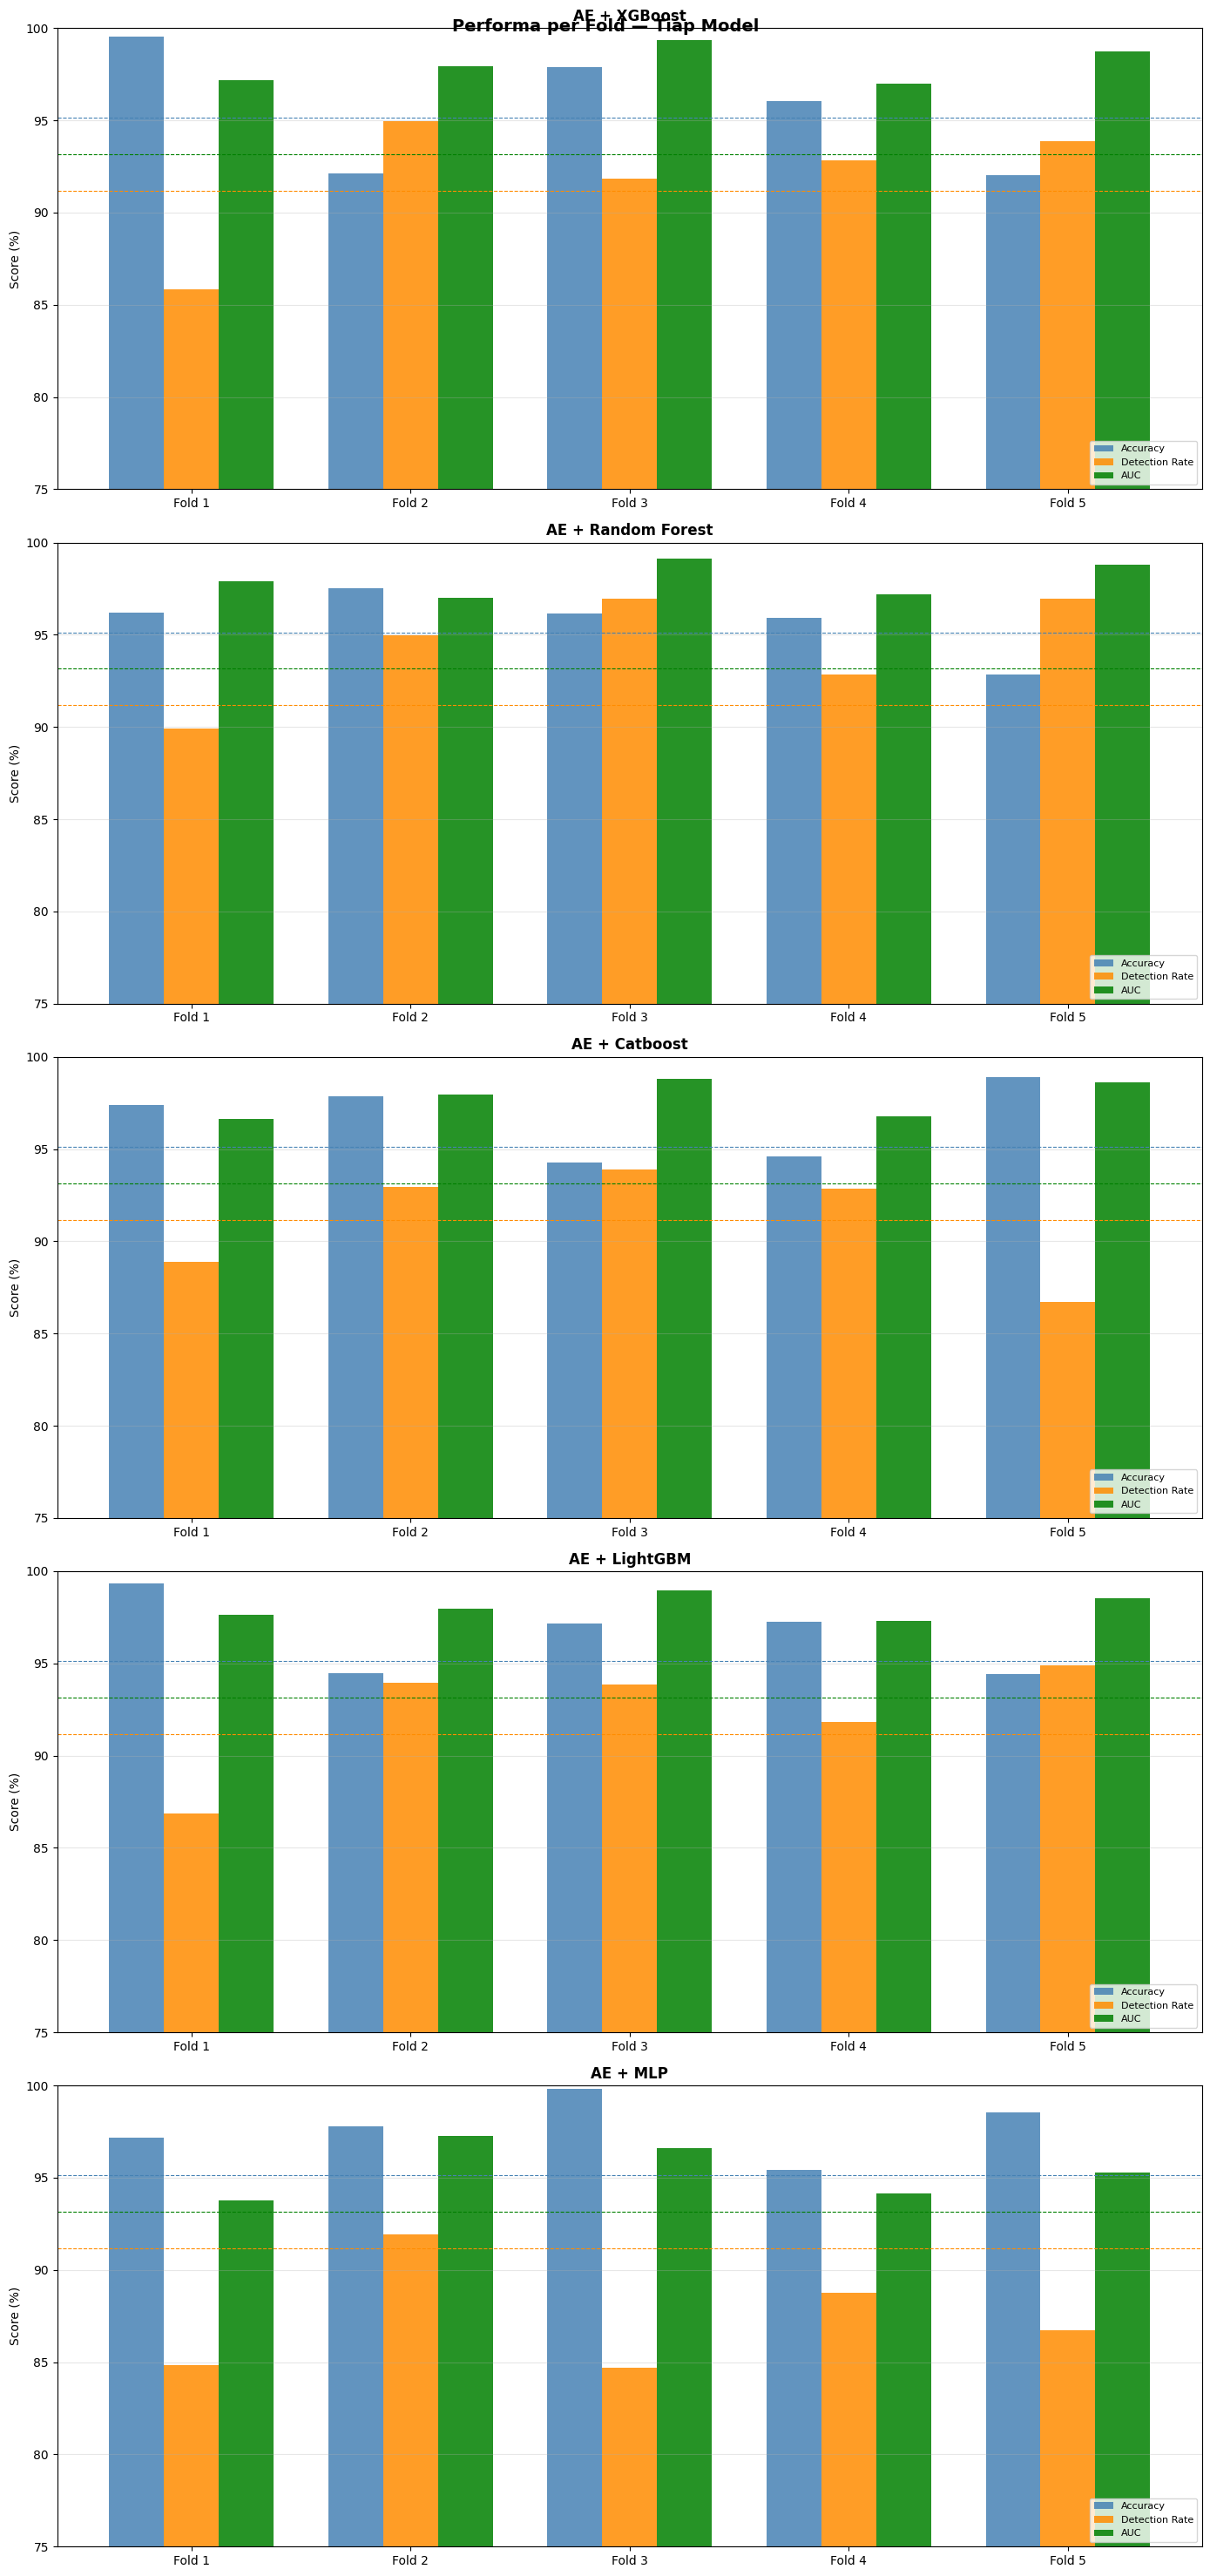

✅ Grafik disimpan sebagai performa_per_fold.png


In [11]:
folds   = ['Fold 1', 'Fold 2', 'Fold 3', 'Fold 4', 'Fold 5']
x_pos   = np.arange(5)
width   = 0.25

fig, axes = plt.subplots(5, 1, figsize=(14, 30))
fig.suptitle('Performa per Fold — Tiap Model', fontsize=14, fontweight='bold')

for idx, (model_name, scores) in enumerate(results.items()):
    ax = axes[idx]
    ax.bar(x_pos - width, scores['acc'], width, label='Accuracy',       color='steelblue',  alpha=0.85)
    ax.bar(x_pos,         scores['dr'],  width, label='Detection Rate', color='darkorange', alpha=0.85)
    ax.bar(x_pos + width, scores['auc'], width, label='AUC',            color='green',      alpha=0.85)

    ax.axhline(y=95.130, color='steelblue',  linestyle='--', linewidth=0.8)
    ax.axhline(y=91.176, color='darkorange', linestyle='--', linewidth=0.8)
    ax.axhline(y=93.156, color='green',      linestyle='--', linewidth=0.8)

    ax.set_title(model_name, fontweight='bold')
    ax.set_xticks(x_pos)
    ax.set_xticklabels(folds)
    ax.set_ylim(75, 100)
    ax.set_ylabel('Score (%)')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('performa_per_fold.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik disimpan sebagai performa_per_fold.png")

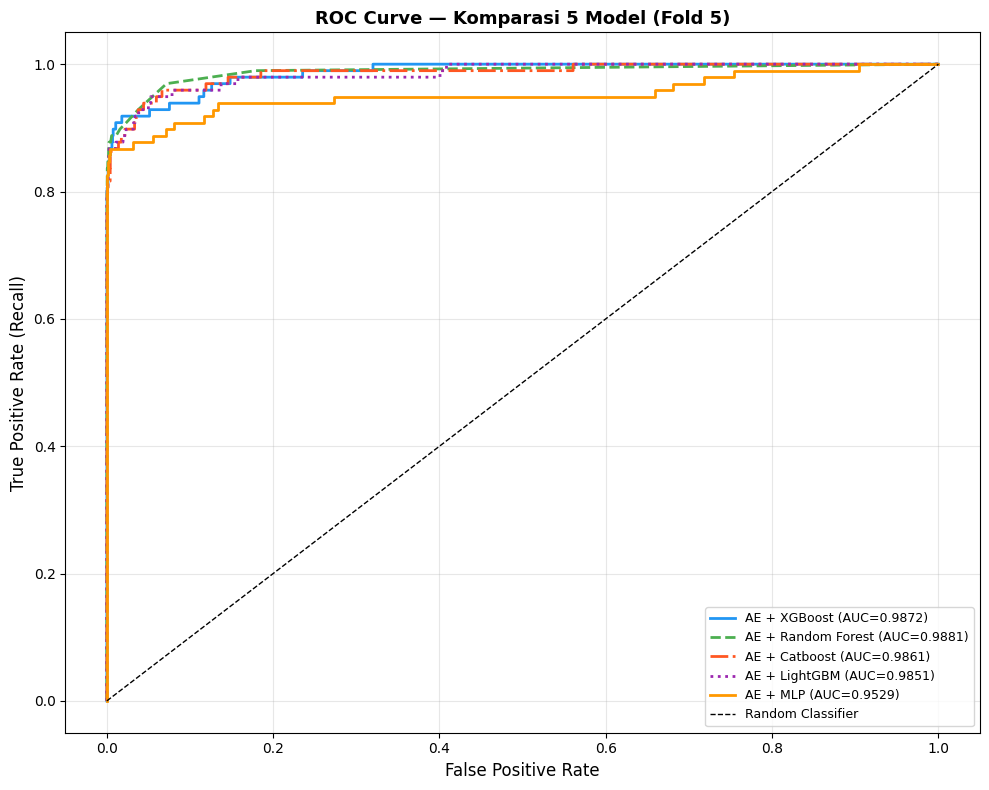

✅ Grafik disimpan sebagai roc_curve_komparasi.png


In [15]:
plt.figure(figsize=(10, 8))
line_styles = ['-', '--', '-.', ':', '-']

for (model_name, (y_t, y_pred, y_prob)), color, ls in zip(
    last_fold.items(), colors, line_styles
):
    fpr, tpr, _ = roc_curve(y_t, y_prob)
    auc_val = roc_auc_score(y_t, y_prob)
    plt.plot(fpr, tpr, color=color, lw=2, linestyle=ls,
             label=f'{model_name} (AUC={auc_val:.4f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Random Classifier')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate (Recall)', fontsize=12)
plt.title('ROC Curve — Komparasi 5 Model (Fold 5)', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('roc_curve_komparasi.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik disimpan sebagai roc_curve_komparasi.png")

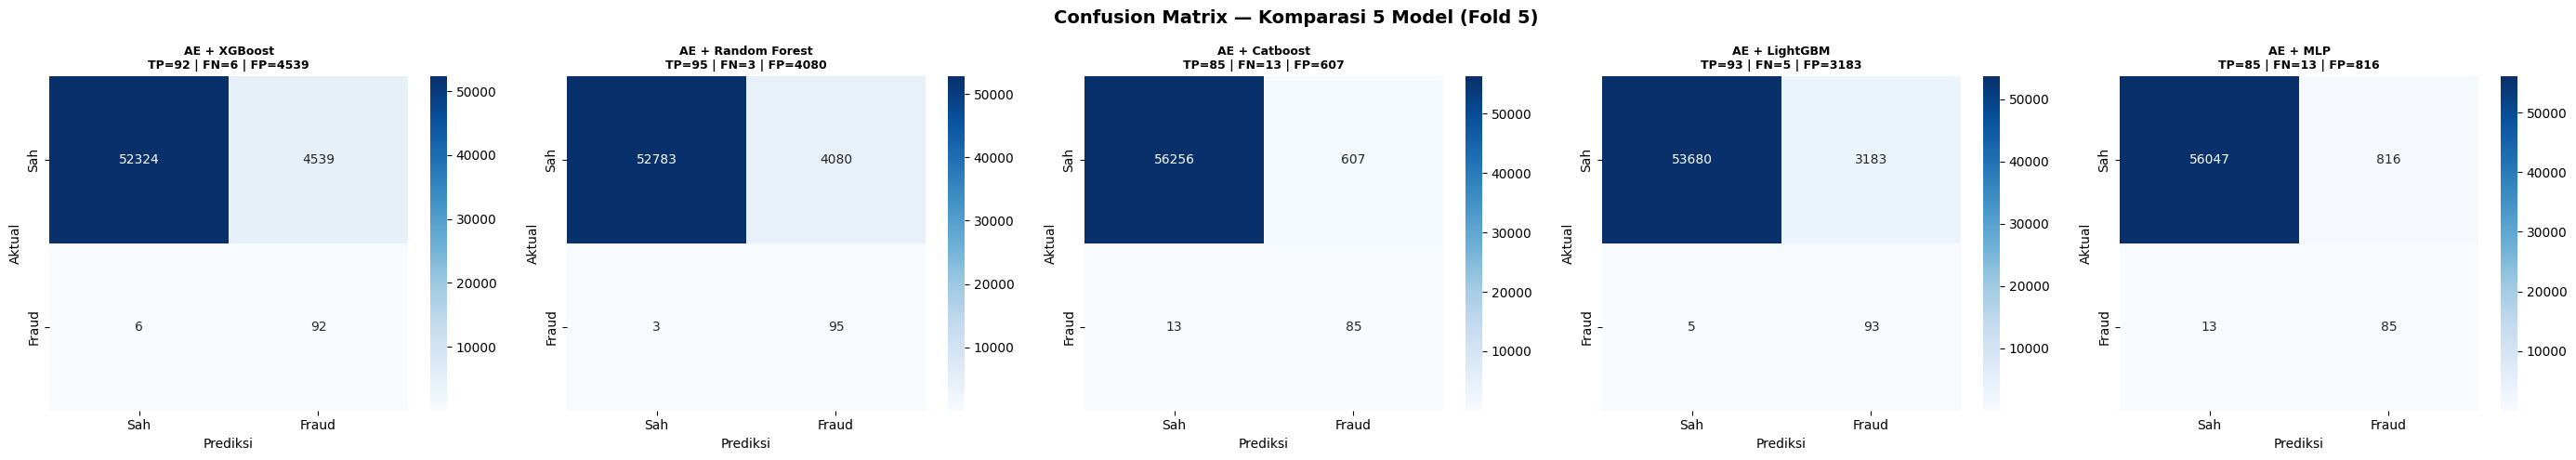

✅ Grafik disimpan sebagai confusion_matrix_komparasi.png


In [16]:
fig, axes = plt.subplots(1, 5, figsize=(28, 5))
fig.suptitle('Confusion Matrix — Komparasi 5 Model (Fold 5)',
             fontsize=14, fontweight='bold')

for ax, (model_name, (y_t, y_pred, y_prob)), color in zip(
    axes, last_fold.items(), colors
):
    cm = confusion_matrix(y_t, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Sah', 'Fraud'],
                yticklabels=['Sah', 'Fraud'])
    tn, fp, fn, tp = cm.ravel()
    ax.set_title(f'{model_name}\nTP={tp} | FN={fn} | FP={fp}',
                 fontsize=9, fontweight='bold')
    ax.set_xlabel('Prediksi')
    ax.set_ylabel('Aktual')

plt.tight_layout()
plt.savefig('confusion_matrix_komparasi.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik disimpan sebagai confusion_matrix_komparasi.png")

In [17]:
for model_name, (y_t, y_pred, y_prob) in last_fold.items():
    print(f"\n{'='*60}")
    print(f"  {model_name}")
    print(f"{'='*60}")
    print(classification_report(
        y_t, y_pred,
        target_names=['Transaksi Sah (0)', 'Penipuan (1)'],
        digits=4
    ))


  AE + XGBoost
                   precision    recall  f1-score   support

Transaksi Sah (0)     0.9999    0.9202    0.9584     56863
     Penipuan (1)     0.0199    0.9388    0.0389        98

         accuracy                         0.9202     56961
        macro avg     0.5099    0.9295    0.4986     56961
     weighted avg     0.9982    0.9202    0.9568     56961


  AE + Random Forest
                   precision    recall  f1-score   support

Transaksi Sah (0)     0.9999    0.9282    0.9628     56863
     Penipuan (1)     0.0228    0.9694    0.0445        98

         accuracy                         0.9283     56961
        macro avg     0.5113    0.9488    0.5036     56961
     weighted avg     0.9983    0.9283    0.9612     56961


  AE + Catboost
                   precision    recall  f1-score   support

Transaksi Sah (0)     0.9998    0.9893    0.9945     56863
     Penipuan (1)     0.1228    0.8673    0.2152        98

         accuracy                         0.9891    

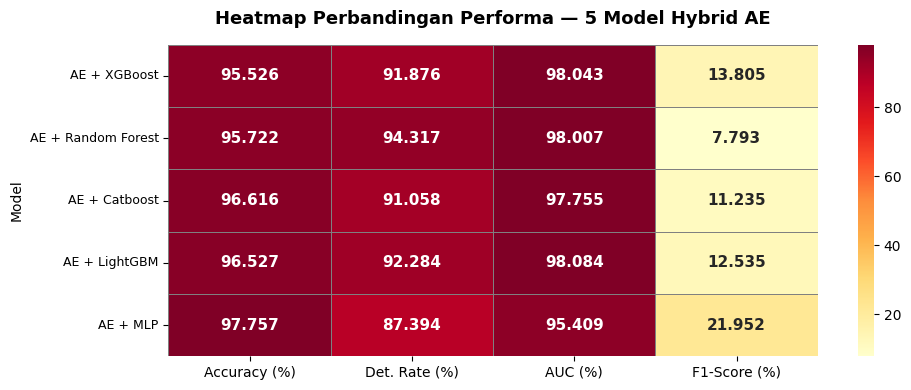

✅ Grafik disimpan sebagai heatmap_komparasi.png


In [18]:
heatmap_data = pd.DataFrame({
    'Model'         : [d['Model'] for d in summary_data],
    'Accuracy (%)'  : [round(d['Accuracy'], 3)       for d in summary_data],
    'Det. Rate (%)' : [round(d['Detection Rate'], 3)  for d in summary_data],
    'AUC (%)'       : [round(d['AUC'], 3)             for d in summary_data],
    'F1-Score (%)'  : [round(d['F1-Score'], 3)        for d in summary_data],
}).set_index('Model')

plt.figure(figsize=(10, 4))
sns.heatmap(heatmap_data, annot=True, fmt='.3f', cmap='YlOrRd',
            linewidths=0.5, linecolor='gray',
            annot_kws={'size': 11, 'weight': 'bold'})
plt.title('Heatmap Perbandingan Performa — 5 Model Hybrid AE',
          fontsize=13, fontweight='bold', pad=15)
plt.xticks(fontsize=10)
plt.yticks(fontsize=9, rotation=0)
plt.tight_layout()
plt.savefig('heatmap_komparasi.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Grafik disimpan sebagai heatmap_komparasi.png")

In [ ]:
best_acc = df_summary.loc[df_summary['Accuracy'].idxmax()]
best_dr  = df_summary.loc[df_summary['Detection Rate'].idxmax()]
best_auc = df_summary.loc[df_summary['AUC'].idxmax()]
best_f1  = df_summary.loc[df_summary['F1-Score'].idxmax()]

print("\n" + "="*60)
print("         KESIMPULAN KOMPARASI 5 MODEL")
print("="*60)
print(f"🏆 Accuracy tertinggi    : {best_acc['Model']} ({best_acc['Accuracy']:.3f}%)")
print(f"🏆 Detection Rate terbaik: {best_dr['Model']}  ({best_dr['Detection Rate']:.3f}%)")
print(f"🏆 AUC tertinggi         : {best_auc['Model']} ({best_auc['AUC']:.3f}%)")
print(f"🏆 F1-Score tertinggi    : {best_f1['Model']}  ({best_f1['F1-Score']:.3f}%)")
print("="*60)
print()
print("Catatan penting:")
print("  • Semua model menggunakan AutoEncoder yang sama sebagai")
print("    feature extractor (latent space 256 dim + MSE).")
print("  • Evaluasi dengan 5-Fold Stratified Cross Validation.")
print("  • Threshold optimal dicari per fold dengan Weighted Youden Index.")
print("  • Target SOTA: Acc≥95.13% | DR≥91.18% | AUC≥93.16%")


         KESIMPULAN KOMPARASI 5 MODEL
🏆 Accuracy tertinggi    : AE + Random Forest (99.470%)
🏆 Detection Rate terbaik: AE + MLP  (93.088%)
🏆 AUC tertinggi         : AE + XGBoost (98.355%)
🏆 F1-Score tertinggi    : AE + Random Forest  (41.084%)

Catatan penting:
  • Semua model menggunakan AutoEncoder yang sama sebagai
    feature extractor (latent space 256 dim + MSE).
  • Evaluasi dengan 5-Fold Stratified Cross Validation.
  • Threshold optimal dicari per fold dengan Weighted Youden Index.
  • Target SOTA: Acc≥95.13% | DR≥91.18% | AUC≥93.16%
